nr of spikes: 0


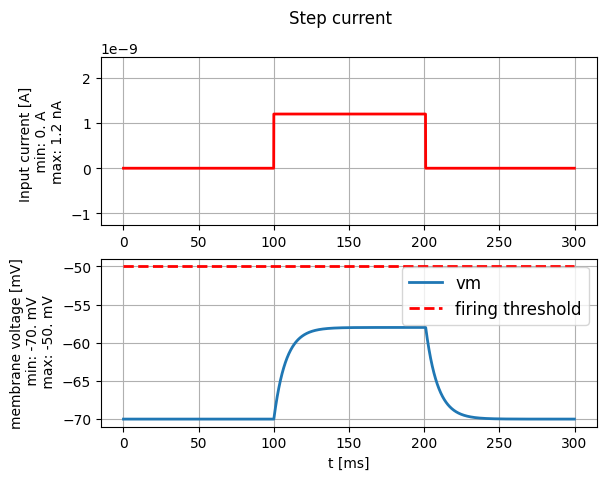

nr of spikes: 5


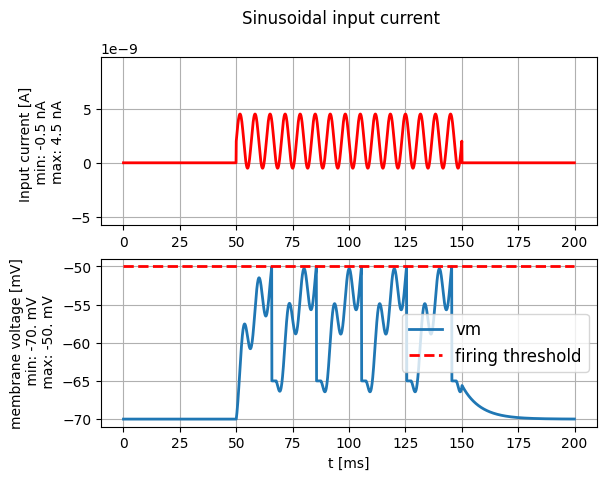

Resting potential: -70. mV
Reset voltage: -65. mV
Firing threshold: -50. mV
Membrane resistance: 10. Mohm
Membrane time-scale: 8. ms
Absolute refractory period: 2. ms


In [1]:
%matplotlib inline
import brian2 as b2
b2.prefs.codegen.target = "numpy"
import matplotlib.pyplot as plt
import numpy as np
from neurodynex3.leaky_integrate_and_fire import LIF
from neurodynex3.tools import input_factory, plot_tools

LIF.getting_started()
LIF.print_default_parameters()

## 1.1 Minimal current

### 1.1.1. Theoretical background

There's a differential equation for the Leaky Integrate-and-Fire -neurons membrane potential $u(t)$, which we must utilize to derive the theoretical minimum to the input current $I(t)$. The differential equation goes as follows:
$$
\tau_m \frac{du}{dt} = -(u(t)-u_{rest}) + RI(t)
$$

When the input current is constant, i.e. $I(t)=I_0$, the differential equation can be solved via standard solving algorithms dedicated to first-order linear ODE's. The process goes as follows:

$$
\begin{aligned}
\tau_m \ u'(t) &= -(u(t)-u_{rest})+RI_0 \\
\tau_m\ v'(t) &= -v(t)+RI_0 && (\text{define}\ v(t):=u(t)-u_{rest}) \\
v'(t) + \frac{1}{\tau_m} v(t) &= \frac{R}{\tau_m}I_0 \\
e^{\frac{t}{\tau_m}}v'(t) + \frac{1}{\tau_m} e^{\frac{t}{\tau_m}} v(t) &= \frac{R}{\tau_m}I_0 e^{\frac{t}{\tau_m}} && (\text{integrating factor}\ \mu = e^{\int{\frac{1}{\tau_m} dt}}=e^{\frac{t}{\tau_m}}) \\
D(e^{\frac{t}{\tau_m}}v) &= \frac{R}{\tau_m}I_0e^{\frac{t}{\tau_m}} \\
\int_0^t{D(e^{\frac{s}{\tau_m}v} ds} &= \frac{R}{\tau_m}I_0 \int_0^t{e^{\frac{s}{\tau_m} ds}} \\
e^{\frac{t}{\tau_m}}v(t)-e^0v(0) &= \frac{R}{\tau_m}I_0 \tau_m (e^{\frac{t}{\tau_m}}-e^0) && \text{(Fundamental Theorem of Calculus)} \\
e^{\frac{t}{\tau_m}}v(t)-v(0) &= RI_0 (e^{\frac{t}{\tau_m}}-1) \\
e^{\frac{t}{\tau_m}}(u(t)-u_{rest}) &= RI_0 (e^{\frac{t}{\tau_m}}-1) && (v(t) = u(t)-u_{rest}\ \text{and}\ v(0) = u(0)-u_{rest} = 0 ) \\
u(t)-u_{rest} &= RI_0(1-e^{-\frac{t}{\tau_m}}) \\
u(t) &= u_{rest} + RI_0(1-e^{-\frac{t}{\tau_m}})
\end{aligned}
$$

Because the time derivative of the membrane potential $u(t)$ is strictly positive $\forall t \geq$ 0, i.e.,
$$
\frac{du}{dt}=\frac{RI_0}{\tau_m}e^{-\frac{t}{\tau_m}}>0,
$$
the voltage trajectory is strictly and monotonically increasing. Consequently, its supremum is attained at the asymptotic limit:
$$
\sup_{t\geq 0 } u(t) = \lim_{t \rightarrow \infty} u(t) = u_{rest}+RI_0
$$

For the neuron to fire, the membrane potential must reach the firing threshold $u_{f}$ for some $t \ge 0$. Therefore, the necessary and sufficient condition for spike generation under an infinitely long pulse is:
$$
\begin{aligned}
\sup_{t\geq 0} u(t) &\geq u_f \Leftrightarrow u_{rest}+RI_0 \geq u_f \Leftrightarrow I_0 \geq \frac{u_f-u_{rest}}{R}
\end{aligned}
$$
Where $u_f$ is the firing threshold.

$\therefore$ the minimum current input is:
$$
I_{min} = \frac{u_f-u_{rest}}{R}
$$

Now if we plug in the default values:

In [2]:
print("firing threshold: {}".format(LIF.FIRING_THRESHOLD))
print("resting potential: {}".format(LIF.V_REST))
print("membrane restistance: {}".format(LIF.MEMBRANE_RESISTANCE))

firing threshold: -50. mV
resting potential: -70. mV
membrane restistance: 10. Mohm


$$
I_{min} = \frac{-50\ mV-(-70\ mV)}{10\ M\ohm}=\frac{20\ mV}{10\ M\ohm} = \frac{20\cdot 10^{-3}\ V}{10\cdot 10^6 \ohm}=2\cdot 10^{-9} \frac{V}{\ohm}=2nA
$$

We can check our answer bu utilizing software:

In [3]:
I_min = (LIF.FIRING_THRESHOLD-LIF.V_REST)/LIF.MEMBRANE_RESISTANCE
print(f"Calculated minimum input current I_min = {I_min}")

Calculated minimum input current I_min = 2. nA


### 1.1.2. Simulation

To inject a step current of amplitude $2\ nA$ for 100ms and plot the membrane voltage $u(t)$, we must do the following:
1. Create the step current by utilizing the get_step_current function from input_factory module
2. Simulate the state of the LIF-neuron with step current as its input current by utilizing simulate_LIF_neuron function from LIF module
3. Plot the voltage and current by utilizing plot_voltage_and_current_traces function from plot_tools module.

nr of spikes: 0


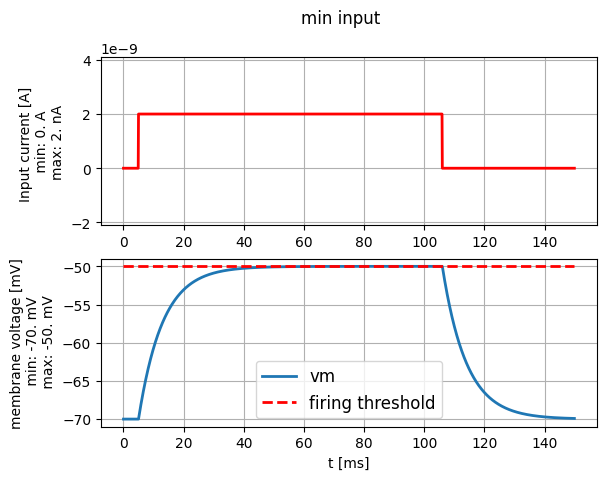

In [4]:
step_current = input_factory.get_step_current(
    t_start=5, t_end=105, unit_time=b2.ms,
    amplitude=I_min)

(state_monitor,spike_monitor) = LIF.simulate_LIF_neuron(input_current=step_current, simulation_time = 150 * b2.ms) 

plot_tools.plot_voltage_and_current_traces(
state_monitor, step_current, title="min input", firing_threshold=LIF.FIRING_THRESHOLD)
print("nr of spikes: {}".format(spike_monitor.count[0]))

As can be seen from the state monitor, the membrane voltage stays under the firing threshold when $I_{min} = 2\ nA$, thus making the LIF-neuron not fire, which can also be deduced from the spike monitor as well. The simulation is run for 150ms which provides a nice view of how the membrane potential slowly decreases after the input current is shut down at $t=105\ ms$. 

## 1.2 f-I Curve

Let's set the amplitude to $I_{min}\cdot 1.01$, to induce a spike.

nr of spikes: 3


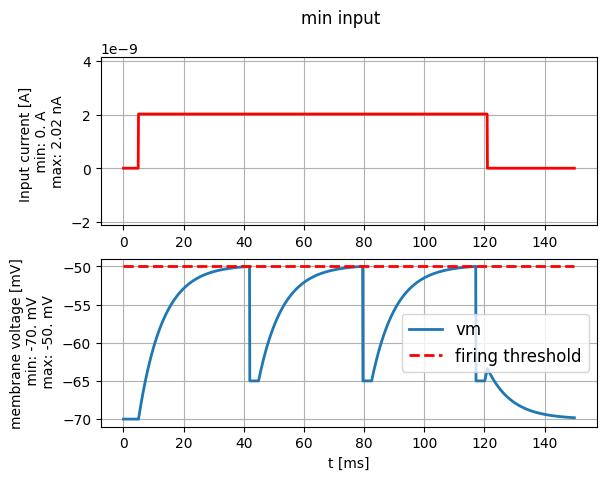

In [5]:
step_current = input_factory.get_step_current(
    t_start=5, t_end=120, unit_time=b2.ms,
    amplitude=I_min*1.01)

state_monitor, spike_monitor = LIF.simulate_LIF_neuron(
    input_current=step_current, simulation_time = 150 * b2.ms,
    abs_refractory_period = 3 * b2.ms) 

plot_tools.plot_voltage_and_current_traces(
state_monitor, step_current, title="min input", firing_threshold=LIF.FIRING_THRESHOLD)
print("nr of spikes: {}".format(spike_monitor.count[0]))

The small cap, or horizontal membrane voltage line at $u_{reset} = -65\ mV$, between the former spike and the subsequent growth of membrane voltage is the refractory period.

Frequency is defined as the reciprocal of the time period:
$$
f = \frac{1}{T}
$$
where $T$ is the total duration of one spike-cycle, or inter-spike interval, meaning $T_{isi} = t_{it}+t_{ref}$ , where $t_{it}$ is integration time and $t_{ref}$ is refractory period.


When input current approaches infinity, the integration time approaches zero. Therefore, the only limiting factor for theoretical maximum frequency is the duration of the refractory period.
$$
f_{max} = \frac{1}{t_{ref}}=\frac{1}{3ms}=333.3\ Hz
$$

To plot the f-I curve, we must create a vector of amplitudes from 0nA to 100nA and simulate the LIF-neuron with each amplitude. Then we must check, how many times did the neuron spike during that time period and add it to the list of frequencies. Then we can plot the values by having amplitudes as explanatory variable and frequencies as the response.

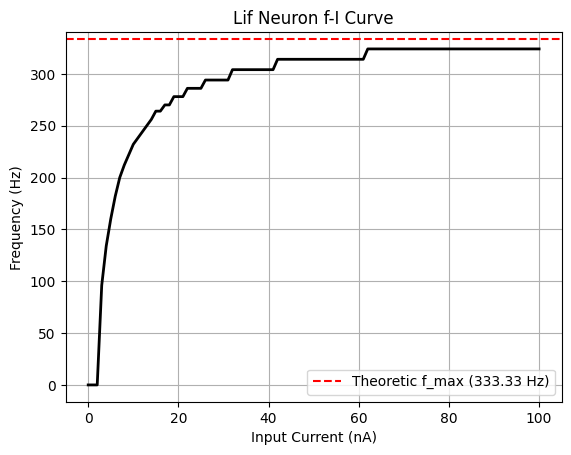

In [6]:
amplitudes = np.arange(0, 101, 1) * b2.nA
frequencies = []
ref_period = 3 * b2.ms
sim_time = 500 * b2.ms

for amp in amplitudes:
    # Create constant input current
    step_current = input_factory.get_step_current(
        t_start = 0,
        t_end = 500,
        unit_time = b2.ms,
        amplitude = amp
    )

    # Simulate the LIF-neuron
    state_monitor, spike_monitor = LIF.simulate_LIF_neuron(
        input_current = step_current,
        simulation_time = sim_time,
        abs_refractory_period = ref_period
    )

    spikes = spike_monitor.count[0]
    freq = spikes / sim_time
    
    # The unit of sim_time is ms, and
    # therefore the unit of freq is 1/ms = Hz.
    # To plot the values, units must be discarded.
    frequencies.append(freq / b2.Hz)

plt.figure()
plt.plot(amplitudes / b2.nA, frequencies, color = "black", linewidth = 2)
plt.axhline(333.33, color = "red", linestyle = "--", label = "Theoretic f_max (333.33 Hz)")
plt.title("Lif Neuron f-I Curve")
plt.xlabel("Input Current (nA)")
plt.ylabel("Frequency (Hz)")
plt.legend()
plt.grid(True)
plt.show()

## 1.3 Experimental LIF parameter estimation

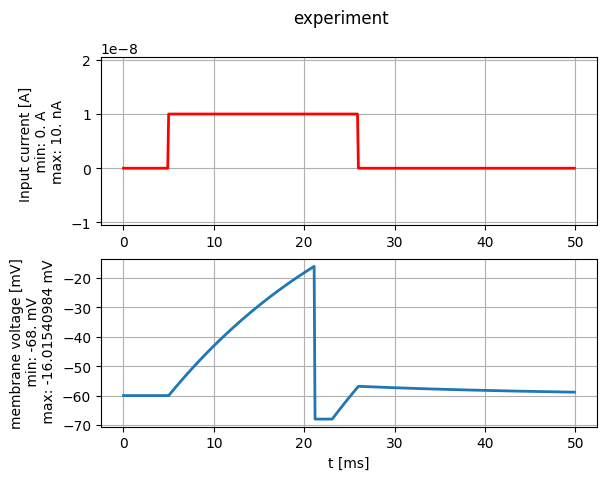

In [7]:
random_param = LIF.get_random_param_set(random_seed = 432)

test_current = input_factory.get_step_current(
    t_start = 5,
    t_end = 25,
    unit_time = b2.ms,
    amplitude = 10 * b2.nA
)

state_monitor, spike_monitor = LIF.simulate_random_neuron(test_current, random_param)

plot_tools.plot_voltage_and_current_traces(state_monitor, test_current, title="experiment")
plt.show() # to prevent Jupyter Notebook from printing unneccessary lines

The resting membrane voltage is $u_{rest} = -60\ mV\ $ which can be deduced from the membrane voltage plot at time $t\in[0,5]$.
The firing threshold lies somewhere around $-16\ mV\ $ and the reset voltage at ~$-67\ mV$.
The absolute refractory period is ~$2\ ms$.
Resistance must be calculated by utilizing Ohm's law $u_\infty-u_{rest} = RI$, where $u_\infty$ is the voltage which the LIF-neuron settles when constant input current is induced and time $t\rightarrow \infty$.
$$
\therefore R = \frac{u_\infty-u_{rest}}{I}
$$
Also, the timescale $\tau_m$ means how long does it take for $x\%$  of the membrane potential to fill when $u_\infty$ is $100\%$.
The solution to the differential equation of the LIF-neuron with constant input current is:
$$
\begin{aligned}
u(t) &= u_{rest} + RI_0(1-e^{-\frac{t}{\tau_m}}) \\
&= u_{rest} + (u_\infty - u_{rest})(1-e^{-\frac{t}{\tau_m}})
\end{aligned}
$$
Let $t=\tau_m$:
$$
\begin{aligned}
u(\tau_m) &= u_{rest} + (u_\infty - u_{rest})(1-e^{-\frac{\tau_m}{\tau_m}}) \\
&= u_{rest} + (u_\infty - u_{rest})(1-e^{-1}) \\
&= u_{rest} + 0.632\cdot (u_\infty - u_{rest})
\end{aligned}
$$
$\therefore x\% =63.2\%$ 

Let's plug in a constant current which does not induce a spike, so that we can estimate the value of $u_\infty$ and $\tau_m$.

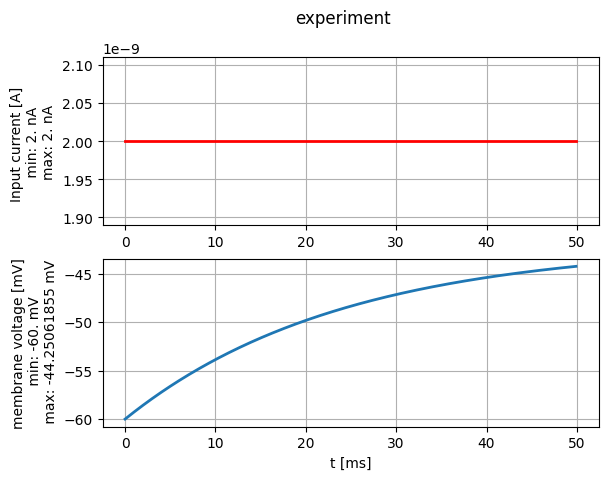

In [8]:
random_param = LIF.get_random_param_set(random_seed = 432)

test_current = input_factory.get_step_current(
    t_start = 0,
    t_end = 50,
    unit_time = b2.ms,
    amplitude = 2 * b2.nA
)

state_monitor, spike_monitor = LIF.simulate_random_neuron(test_current, random_param)

plot_tools.plot_voltage_and_current_traces(state_monitor, test_current, title="experiment")
plt.show() # to prevent Jupyter Notebook from printing unneccessary lines

The membrane voltage seems to be approaching maybe around $-42\ mV$ which means that we can approximate $u_\infty=-42\ mV$ when $I=2\ nA$.

$$
\therefore R = \frac{-42\ mV-(-60mV)}{2\ nA}=\frac{18\ mV}{2\ nA}=9 000k\ohm
$$

and $\tau_m \approx 27 ms$

Let's print the random generated values and check how closely we approximated:

In [9]:
LIF.print_obfuscated_parameters(random_param)

Resting potential: -60. mV
Reset voltage: -68. mV
Firing threshold: -16. mV
Membrane resistance: 9. Mohm
Membrane time-scale: 24. ms
Absolute refractory period: 2. ms


## 1.4 Sinusoidal input and subthreshold response

Whereas the get_step_current function injects a piecewise constant input current—meaning a $1\text{ ms}$ time step is sufficient—a high-frequency sinusoidal current requires a finer time resolution for both accurate numerical simulation and smooth plotting. For a frequency of $f = 250\text{ Hz}$, the period of a single oscillation is
$$
T=\frac{1}{f}=\frac{1}{250\text{ Hz}}=4\text{ ms}
$$
Sampling this signal at $1\text{ ms}$ intervals yields only 4 points per period, severely distorting the waveform. By decreasing unit_time from $1\text{ ms}$ to $0.1\text{ ms}$ and scaling the step indices t_start and t_end by a factor of 10 (to $200$ and $1000$), we achieve a resolution of 40 samples per period while keeping the physical current active between $20\text{ ms}$ and $100\text{ ms}$.

nr of spikes: 0


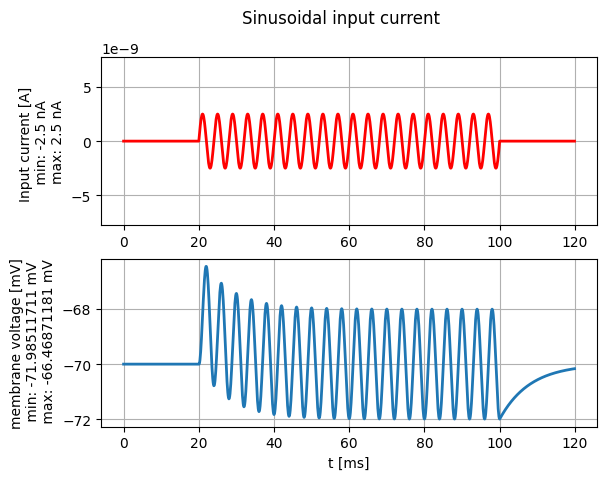

In [10]:
sinusoidal_current = input_factory.get_sinusoidal_current(
    t_start = 200, 
    t_end = 1000, 
    unit_time=0.1 * b2.ms,
    amplitude= 2.5 * b2.namp,
    frequency=250*b2.Hz, 
    direct_current=0. * b2.namp)

(state_monitor, spike_monitor) = LIF.simulate_LIF_neuron(input_current=sinusoidal_current,
                                                         simulation_time = 120 * b2.ms,
                                                         firing_threshold=0*b2.mV)

plot_tools.plot_voltage_and_current_traces(state_monitor, sinusoidal_current, title="Sinusoidal input current")
print("nr of spikes: {}".format(spike_monitor.count[0]))

### 1.4.2 Amplitude of subthreshold oscillations as a function of input frequency

First, the different frequencies ranging from 10 Hz to 1 kHz are compiled as elements of a NumPy array. Next, the LIF neuron is simulated for each stored frequency using a for loop, and the voltages for each time step are recorded from the simulation. The time points are also recorded separately. Then, we isolate the time interval where the oscillating sinusoidal voltage has stabilized, meaning its peaks and troughs remain consistent across cycles. Because the initial potential might differ from the zero point of this sine wave, the stabilized waveform develops towards the end. Therefore, we can slice a specific time interval from the latter part. Using these time points, we find the corresponding voltages and calculate the amplitude, i.e., $(\text{max voltage} - \text{min voltage}) / 2$. Afterwards, the amplitude is appended to a list, and the loop repeats this process for every frequency. Finally, the values in the list are plotted as a function of frequency in the usual manner.

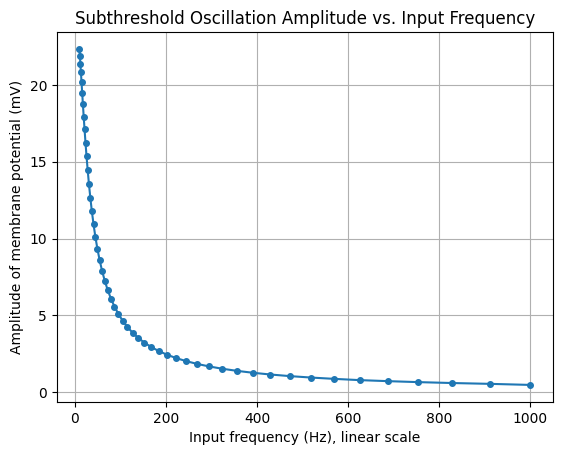

In [11]:
# Frequencies gathered logarithmically to create smoother line.
frequencies = np.logspace(np.log10(10), np.log10(1000), 50) * b2.Hz
amplitudes = []

for freq in frequencies:
    sinusoidal_current = input_factory.get_sinusoidal_current(
    t_start = 200, 
    t_end = 2000, 
    unit_time = 0.1 * b2.ms,
    amplitude = 2.5 * b2.namp,
    frequency = freq, 
    direct_current = 0. * b2.namp)

    state_monitor, spike_monitor = LIF.simulate_LIF_neuron(input_current = sinusoidal_current,
                                                         simulation_time = 220 * b2.ms,
                                                         firing_threshold= 100 * b2.mV)
    
    voltages = state_monitor.v[0]
    times = state_monitor.t

    # Element t gets assigned True if 100 < t < 200.
    steady_state_mask = (times > 100 * b2.ms) & (times < 200 * b2.ms)
    
    # Gathers voltages from timeframe 100 < t < 200.
    steady_state_v = voltages[steady_state_mask]

    amplitude = (max(steady_state_v) - min(steady_state_v))/2

    amplitudes.append(amplitude / b2.ms)

# On linear scale
plt.figure()
plt.plot(frequencies / b2.Hz, amplitudes, marker = "o", markersize = 4, linestyle = "-")
plt.xlabel("Input frequency (Hz), linear scale")
plt.ylabel("Amplitude of membrane potential (mV)")
plt.title("Subthreshold Oscillation Amplitude vs. Input Frequency")
plt.grid(True)
plt.show()

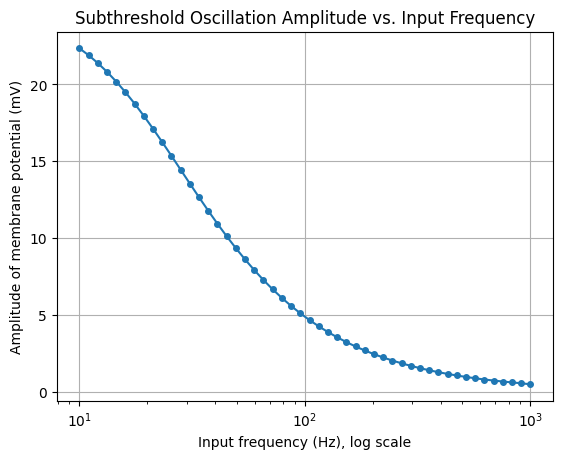

In [12]:
# Logarithmic scale
plt.figure()
plt.plot(frequencies / b2.Hz, amplitudes, marker = "o", markersize = 4, linestyle = "-")
plt.xscale("log")
plt.xlabel("Input frequency (Hz), log scale")
plt.ylabel("Amplitude of membrane potential (mV)")
plt.title("Subthreshold Oscillation Amplitude vs. Input Frequency")
plt.grid(True)
plt.show()